# Imprinting Analysis with Control Reference: GSE74738

This notebook runs imprintomeR on **GSE74738**, an Illumina 450K cohort of placentas and related samples with a large group of normal controls. Because the cohort has its own controls, scores can be **centred on the controls** instead of the fixed 0.5 reference, and the per-ICR calls use both of their criteria (|deviation| ≥ 0.075 and |z| ≥ 3).

The cohort contains genetically defined parent-of-origin imbalances, which give expected directions:

| Group | Samples | Parental genomes | Expected shift |
|---|---:|---|---|
| control | 53 | balanced | none (reference) |
| CHM (complete hydatidiform mole) | 1 | paternal only (androgenetic) | paternal gain + maternal loss |
| diandric triploid | 5 | 2 paternal : 1 maternal | towards paternal gain |
| digynic triploid | 5 | 1 paternal : 2 maternal | towards maternal gain |
| IUGR, LOPET, chromosomally normal miscarriage, Ab. MSS | 15 | balanced | none expected |

Placental imprinting includes placenta-specific DMRs, so results describe placenta and should not be read as blood or adult-tissue behaviour.

You will:

1. download the raw IDATs and metadata from GEO (or reuse a QC set from the command-line workflow);
2. run methylation-array QC;
3. score imprinting against the fixed 0.5 reference and against the cohort's controls;
4. score each ICR and summarize altered ICRs per sample;
5. add bootstrap intervals, the origin permutation test and a control-calibrated IDS cutoff;
6. score the chr11p15 and chr20q13 locus panels;
7. visualize and export the results.

## Phase 1: Setup

In [1]:
library(imprintomeR)
library(dplyr)

set.seed(2026)
options(repr.plot.width = 10, repr.plot.height = 8)
packageVersion("imprintomeR")

[1] '1.5.0'


## Phase 2: Data

Choose **one** of the two options.

### Option A: raw IDATs from GEO

The raw archive (`GSE74738_RAW.tar`) is downloaded once into `GSE74738_raw/`. This cell is the slow one; skip it when you use Option B.

In [ ]:
library(GEOquery)
geo_gse <- "GSE74738"
raw_dir <- "GSE74738_raw"
dir.create(raw_dir, showWarnings = FALSE)

gse   <- getGEO(geo_gse, GSEMatrix = TRUE, getGPL = FALSE)
pdata <- pData(gse[[1]])

supp <- getGEOSuppFiles(geo_gse, baseDir = raw_dir)
untar(rownames(supp)[grepl("RAW\\.tar$", rownames(supp))], exdir = file.path(raw_dir, "idats"))

Build the QC metadata: one row per sample with `Sample_Name`, `Sample_Group` (from the GEO `status/group` field) and `Basename`, the absolute IDAT path prefix.

In [ ]:
idat_grn <- list.files(file.path(raw_dir, "idats"), pattern = "_Grn\\.idat(\\.gz)?$", full.names = TRUE)
idat_map <- data.frame(
  Basename      = normalizePath(sub("_Grn\\.idat(\\.gz)?$", "", idat_grn)),
  geo_accession = sub("_.*$", "", basename(idat_grn)),
  stringsAsFactors = FALSE
)

group_col <- grep("group:ch1$", colnames(pdata), value = TRUE)[1]
meta_qc <- data.frame(
  Sample_Name   = pdata$geo_accession,
  Sample_Group  = trimws(pdata[[group_col]]),
  Title         = pdata$title,
  stringsAsFactors = FALSE
)
meta_qc$Basename <- idat_map$Basename[match(meta_qc$Sample_Name, idat_map$geo_accession)]
meta_qc <- meta_qc[!is.na(meta_qc$Basename), ]

table(meta_qc$Sample_Group)

Run QC (450K). `Final.QC` is PASS when at least 95% of probes are detected at p < 0.05 and the bisulfite conversion I control metrics are at least 1.

In [ ]:
qcset <- runMethQC(meta_qc, platform = "450K", outdir = "GSE74738_qc", prefix = "450k")

### Option B: QC set from the command-line workflow

If you already ran `run_meth_QC.R` (for example `--platform 450K --outdir qc_results`), load its QC set instead.

In [2]:
qcset <- readRDS("qc_results/450k/data/450k_qcset.rds")

## Phase 3: QC review

In [3]:
qc_matrix <- qc_tables(qcset)[["QC_matrix"]]
table(qc_matrix$Final.QC)
qc_params(qcset)$normalization


PASS 
  79 
[1] "noob"


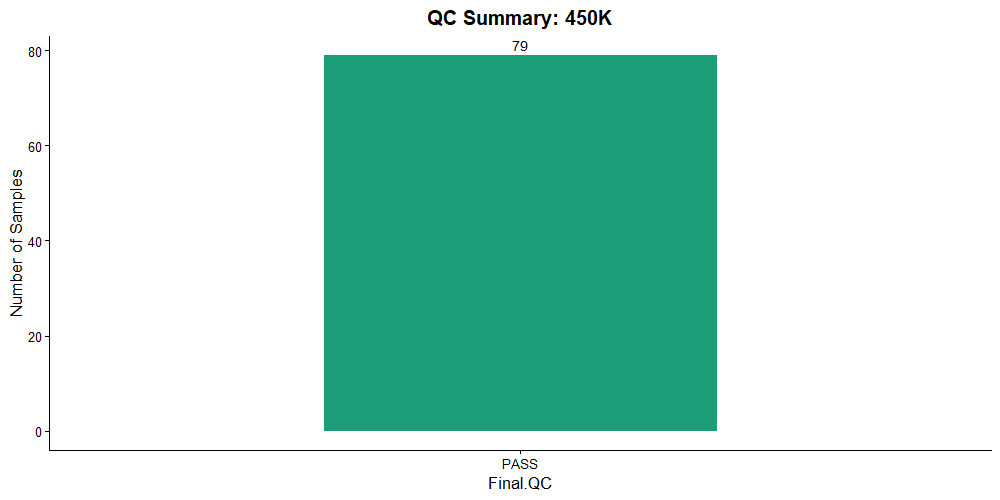

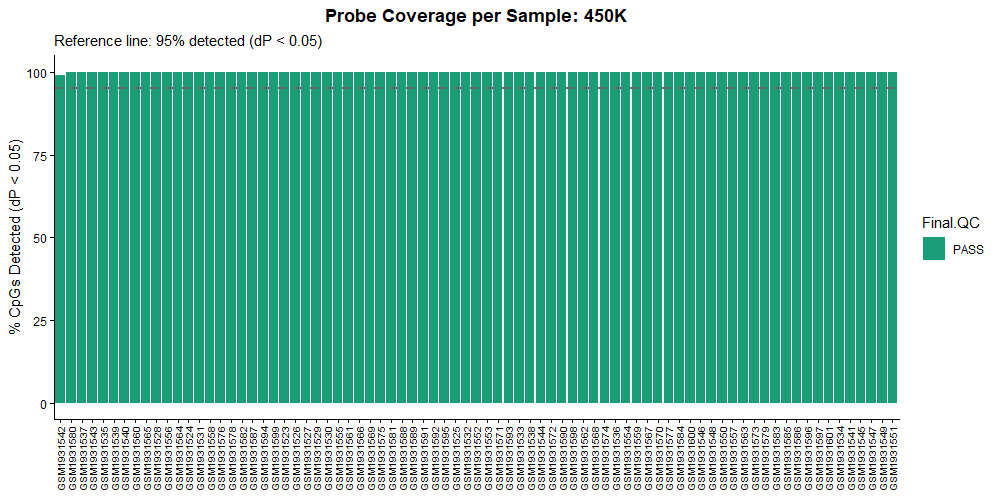

In [4]:
options(repr.plot.width = 10, repr.plot.height = 5)
print(plot(qcset, type = "qc_bar"))
print(plot(qcset, type = "probe_coverage"))

## Phase 4: ImprintomeSet and sample-level scores

In [5]:
qc_pass <- subsetMethQC(qcset, final_qc = "PASS")
x <- as.ImprintomeSet(qc_pass, genome = "hg38")
imprintomeR::summarize(x)$object   # dplyr, attached later, masks summarize()
table(meta(x)$Sample_Group)

  assay genome beta_nrow beta_ncol meta_nrow meta_ncol probeset_type
1  450K   hg38    485512        79        79        27          list
  probeset_nrow probeset_ncol       probeset_info
1            11            NA list-based probeset

                           Ab. MSS                                CHM 
                                 2                                  1 
Chromosomically Normal Miscarriage                            control 
                                 5                                 53 
                 diandric triploid                   digynic triploid 
                                 5                                  5 
                              IUGR                              LOPET 
                                 5                                  3 


Score the `selected` panel (gametic ICRs by default) twice: against the fixed 0.5 reference, and centred on the cohort's controls (`reference_group = "control"`; each control is scored leave-one-out). `icr = TRUE` adds the per-ICR tables to the control-centred run.

In [6]:
x <- runImprintome(x, probeset = "selected")                                         # fixed 0.5 reference
x <- runImprintome(x, probeset = "selected", reference_group = "control", icr = TRUE)  # centred on controls
names(results(x))


	[meta dim: 79 x 27 ]
	[beta dim: 485512 x 80 ]
	[meta dim: 79 x 27 ]
	[beta dim: 485512 x 79 ]
	[SubsetBeta] subset by probeset [query: 782; matched probes: 782 ]

	[meta dim: 79 x 27 ]
	[beta dim: 485512 x 80 ]
	[meta dim: 79 x 27 ]
	[beta dim: 485512 x 79 ]
	[SubsetBeta] subset by probeset [query: 782; matched probes: 782 ]

	[meta dim: 79 x 27 ]
	[beta dim: 485512 x 80 ]
	[meta dim: 79 x 27 ]
	[beta dim: 485512 x 79 ]
	[SubsetBeta] subset by probeset [query: 782; matched probes: 782 ]
[1] "AnalyzeImprintStatus.selected"             
[2] "AnalyzeImprintStatus.selected.ref-controls"
[3] "ICRStatus.selected"                        
[4] "ICRSummary.selected"                       


In [7]:
group_summary <- function(tab, reference) {
  tab %>%
    group_by(Sample_Group) %>%
    summarise(n = n(), median_IDS = round(median(IDS), 3), max_IDS = round(max(IDS), 3),
              top_mechanism = names(sort(table(Mechanism), decreasing = TRUE))[1], .groups = "drop") %>%
    mutate(reference = reference)
}
res <- results(x)
bind_rows(group_summary(res[["AnalyzeImprintStatus.selected"]], "fixed 0.5"),
          group_summary(res[["AnalyzeImprintStatus.selected.ref-controls"]], "controls"))

# A tibble: 16 × 6
   Sample_Group                     n median_IDS max_IDS top_mechanism reference
   <chr>                        <int>      <dbl>   <dbl> <chr>         <chr>    
 1 Ab. MSS                          2      0.032   0.044 ROI           fixed 0.5
 2 CHM                              1      0.565   0.565 Pat-Gain+Mat… fixed 0.5
 3 Chromosomically Normal Misc…     5      0.034   0.058 ROI           fixed 0.5
 4 IUGR                             5      0.045   0.068 ROI           fixed 0.5
 5 LOPET                            3      0.027   0.033 ROI           fixed 0.5
 6 control                         53      0.033   0.162 ROI           fixed 0.5
 7 diandric triploid                5      0.1     0.171 ROI           fixed 0.5
 8 digynic triploid                 5      0.141   0.158 ROI           fixed 0.5
 9 Ab. MSS                          2      0.012   0.018 ROI           controls 
10 CHM                              1      0.492   0.492 Pat-Gain+Mat… controls 
11 Chromo

Samples with a parent-of-origin imbalance: the androgenetic mole falls in Pat-Gain+Mat-Loss; triploids shift less, towards the paternal (diandric) or maternal (digynic) side. Compare their angles.

In [8]:
status <- res[["AnalyzeImprintStatus.selected.ref-controls"]]
status %>%
  filter(Sample_Group %in% c("CHM", "diandric triploid", "digynic triploid")) %>%
  select(Sample_Name, Sample_Group, IDS, Angle, Mechanism) %>%
  arrange(Sample_Group, Angle)

           Sample_Name      Sample_Group   IDS Angle         Mechanism
GSM1931562  GSM1931562               CHM 0.492 316.3 Pat-Gain+Mat-Loss
GSM1931559  GSM1931559 diandric triploid 0.075 307.5               ROI
GSM1931561  GSM1931561 diandric triploid 0.076 308.1               ROI
GSM1931560  GSM1931560 diandric triploid 0.126 325.6               ROI
GSM1931552  GSM1931552 diandric triploid 0.114 329.6               ROI
GSM1931556  GSM1931556 diandric triploid 0.169 351.0               ROI
GSM1931553  GSM1931553  digynic triploid 0.124 108.1               ROI
GSM1931555  GSM1931555  digynic triploid 0.112 114.7               ROI
GSM1931558  GSM1931558  digynic triploid 0.106 121.6               ROI
GSM1931557  GSM1931557  digynic triploid 0.133 131.4               ROI
GSM1931554  GSM1931554  digynic triploid 0.108 134.2               ROI


## Phase 5: Per-ICR scores

Each ICR is scored on its own: the median of (beta − control median) over its probes, called altered when |deviation| ≥ 0.075 and |z| ≥ 3 against the controls. The summary counts altered ICRs per sample and flags multi-locus disturbance (MLID) when they lie on at least two chromosomes. Per-ICR scores cover all annotated ICRs, secondary DMRs included.

In [9]:
icr_table   <- res[["ICRStatus.selected"]]
icr_summary <- res[["ICRSummary.selected"]]

icr_summary %>%
  group_by(Sample_Group) %>%
  summarise(n = n(), median_altered = median(n_altered), max_altered = max(n_altered),
            median_gain = median(n_gain), median_loss = median(n_loss), MLID = sum(MLID), .groups = "drop")

# A tibble: 8 × 7
  Sample_Group        n median_altered max_altered median_gain median_loss  MLID
  <chr>           <int>          <dbl>       <int>       <dbl>       <dbl> <int>
1 Ab. MSS             2              0           0           0           0     0
2 CHM                 1             26          26           5          21     1
3 Chromosomicall…     5              0           1           0           0     0
4 IUGR                5              1           3           0           1     2
5 LOPET               3              0           1           0           0     0
6 control            53              0           2           0           0     1
7 diandric tripl…     5              6           8           1           4     5
8 digynic triplo…     5             13          16          13           0     5


In [10]:
# Median per-ICR deviation by annotated parental origin in the triploids
icr_table %>%
  filter(Sample_Group %in% c("diandric triploid", "digynic triploid")) %>%
  group_by(Sample_Group, ORIGIN) %>%
  summarise(median_deviation = round(median(deviation), 3), .groups = "drop")

# Count gametic ICRs only
SummarizeICRStatus(icr_table, dmr_type = "gametic") %>%
  select(Sample_Name, Sample_Group, n_icrs, n_altered, MLID) %>%
  arrange(desc(n_altered)) %>%
  head(15)

# A tibble: 4 × 3
  Sample_Group      ORIGIN   median_deviation
  <chr>             <chr>               <dbl>
1 diandric triploid maternal           -0.054
2 diandric triploid paternal            0.12 
3 digynic triploid  maternal            0.091
4 digynic triploid  paternal           -0.039
   Sample_Name      Sample_Group n_icrs n_altered  MLID
1   GSM1931562               CHM     30        22  TRUE
2   GSM1931553  digynic triploid     30        16  TRUE
3   GSM1931555  digynic triploid     30        15  TRUE
4   GSM1931557  digynic triploid     30        13  TRUE
5   GSM1931558  digynic triploid     30        13  TRUE
6   GSM1931554  digynic triploid     30         9  TRUE
7   GSM1931560 diandric triploid     30         7  TRUE
8   GSM1931559 diandric triploid     30         5  TRUE
9   GSM1931561 diandric triploid     30         4  TRUE
10  GSM1931543              IUGR     30         3  TRUE
11  GSM1931539              IUGR     30         2  TRUE
12  GSM1931552 diandric triploid  

## Phase 6: Uncertainty and calibration

With a control reference, all three options apply:

- `n_boot`: bootstrap intervals for IDS and Angle, and `Mechanism_support`, the fraction of replicates in the reported sector (use ≥ 1,000 replicates for reporting; 200 keep this fast);
- `n_perm`: a permutation test of whether the deviation depends on the annotated parental origin (`origin_perm_p`);
- `CalibrateIDS()`: an IDS cutoff from the controls' own IDS distribution, here its 99th percentile.

In [11]:
x <- runImprintome(x, probeset = "selected", reference_group = "control",
                   n_boot = 200, n_perm = 200, seed = 2026, result_name = "selected.uncertainty")
unc <- results(x)[["selected.uncertainty"]]
unc %>%
  filter(Sample_Group != "control") %>%
  select(Sample_Name, Sample_Group, IDS, IDS_lower, IDS_upper, Angle, Mechanism, Mechanism_support, origin_perm_p) %>%
  arrange(desc(IDS)) %>%
  head(15)


	[meta dim: 79 x 27 ]
	[beta dim: 485512 x 80 ]
	[meta dim: 79 x 27 ]
	[beta dim: 485512 x 79 ]
	[SubsetBeta] subset by probeset [query: 782; matched probes: 782 ]
           Sample_Name                       Sample_Group   IDS IDS_lower
GSM1931562  GSM1931562                                CHM 0.492     0.396
GSM1931556  GSM1931556                  diandric triploid 0.169     0.158
GSM1931557  GSM1931557                   digynic triploid 0.133     0.122
GSM1931560  GSM1931560                  diandric triploid 0.126     0.112
GSM1931553  GSM1931553                   digynic triploid 0.124     0.115
GSM1931552  GSM1931552                  diandric triploid 0.114     0.100
GSM1931555  GSM1931555                   digynic triploid 0.112     0.086
GSM1931554  GSM1931554                   digynic triploid 0.108     0.080
GSM1931558  GSM1931558                   digynic triploid 0.106     0.089
GSM1931561  GSM1931561                  diandric triploid 0.076     0.056
GSM1931559  GSM193155

In [12]:
cal <- CalibrateIDS(unc, controls = "control", method = "quantile", probs = 0.99)
attr(cal, "calibration")
table(cal$Sample_Group, cal$Status_calibrated)

    method probs cutoff n_controls control_median control_max n_cases AUC
1 quantile  0.99  0.118         53          0.022       0.137      NA  NA
  sensitivity specificity
1          NA          NA
                                    
                                     Imprinting Alteration Normal
  Ab. MSS                                                0      2
  CHM                                                    1      0
  Chromosomically Normal Miscarriage                     0      5
  control                                                1     52
  diandric triploid                                      2      3
  digynic triploid                                       2      3
  IUGR                                                   0      5
  LOPET                                                  0      3


## Phase 7: Locus panels (chr11p15 and chr20q13)

In [13]:
x <- runImprintome(x, probeset = "chr11p15", reference_group = "control")
x <- runImprintome(x, probeset = "chr20q13", reference_group = "control")
res <- results(x)
bind_rows(group_summary(res[["AnalyzeImprintStatus.chr11p15.ref-controls"]], "chr11p15"),
          group_summary(res[["AnalyzeImprintStatus.chr20q13.ref-controls"]], "chr20q13"))


	[meta dim: 79 x 27 ]
	[beta dim: 485512 x 80 ]
	[meta dim: 79 x 27 ]
	[beta dim: 485512 x 79 ]
	[SubsetBeta] subset by probeset [query: 82; matched probes: 82 ]

	[meta dim: 79 x 27 ]
	[beta dim: 485512 x 80 ]
	[meta dim: 79 x 27 ]
	[beta dim: 485512 x 79 ]
	[SubsetBeta] subset by probeset [query: 143; matched probes: 136 ]
# A tibble: 16 × 6
   Sample_Group                     n median_IDS max_IDS top_mechanism reference
   <chr>                        <int>      <dbl>   <dbl> <chr>         <chr>    
 1 Ab. MSS                          2      0.006   0.011 ROI           chr11p15 
 2 CHM                              1      0.582   0.582 Pat-Gain+Mat… chr11p15 
 3 Chromosomically Normal Misc…     5      0.022   0.036 ROI           chr11p15 
 4 IUGR                             5      0.031   0.041 ROI           chr11p15 
 5 LOPET                            3      0.02    0.026 ROI           chr11p15 
 6 control                         53      0.025   0.142 ROI           chr11p15 
 7 di

## Phase 8: Visualizations

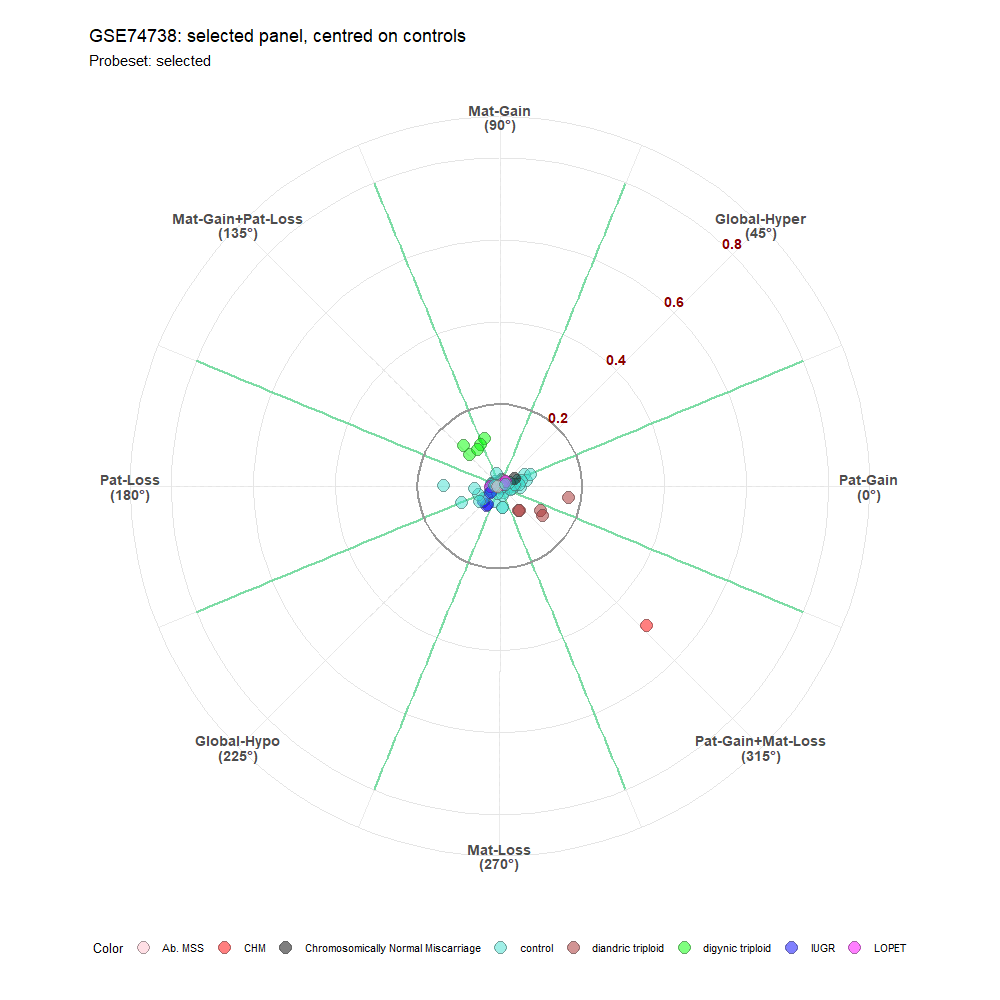

In [14]:
options(repr.plot.width = 10, repr.plot.height = 10)
plot(x, plot_type = "polar", probeset = "selected",
     result_name = "AnalyzeImprintStatus.selected.ref-controls",
     title = "GSE74738: selected panel, centred on controls")

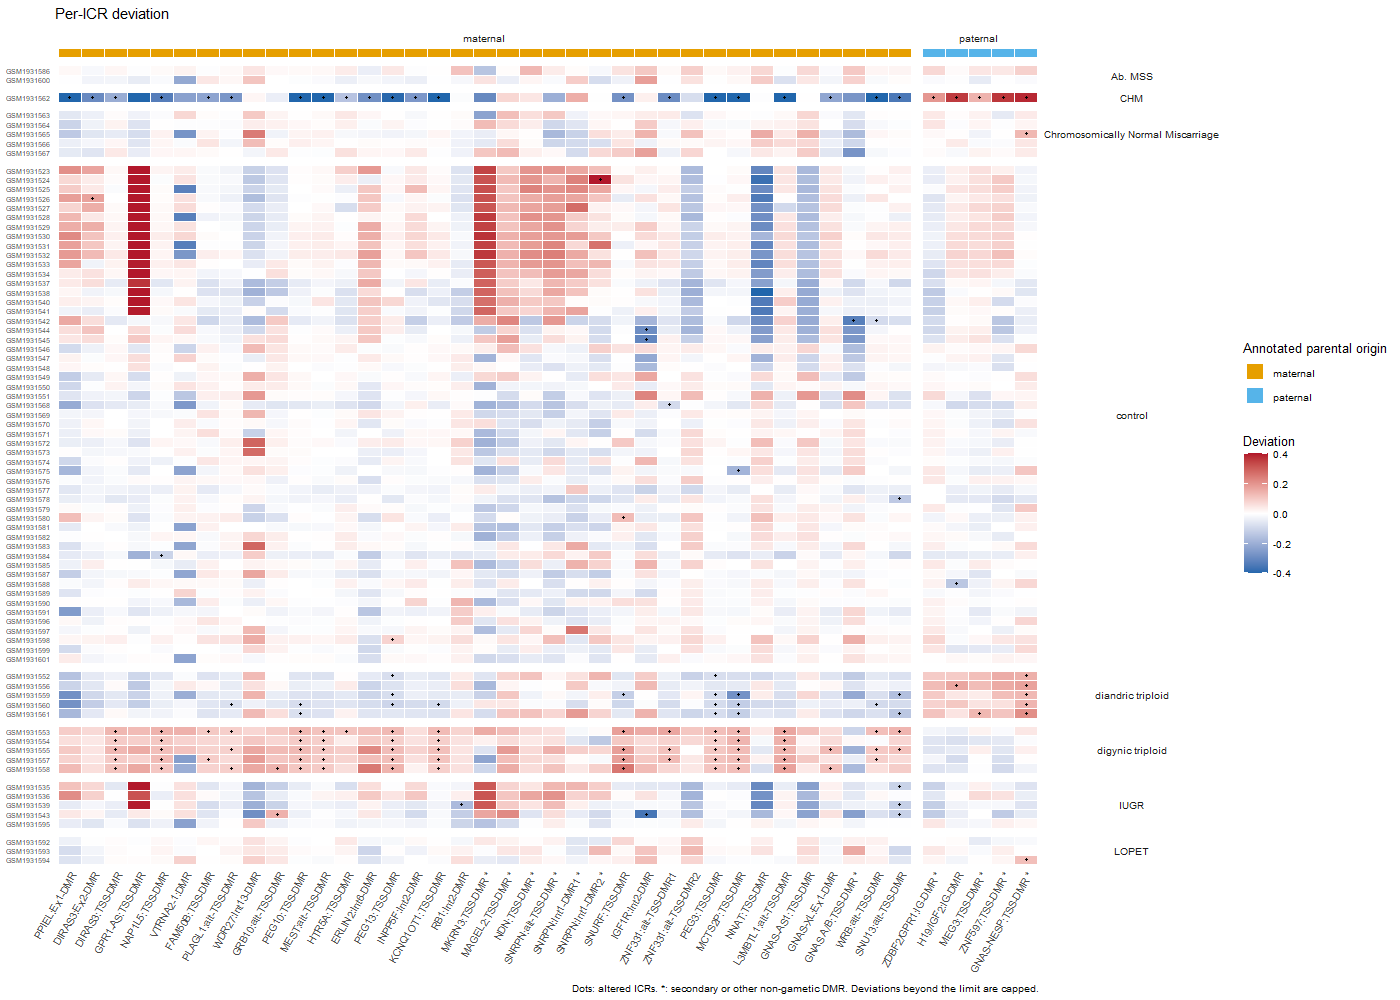

In [15]:
options(repr.plot.width = 14, repr.plot.height = 10)
plot(x, plot_type = "icr_heatmap", probeset = "selected")

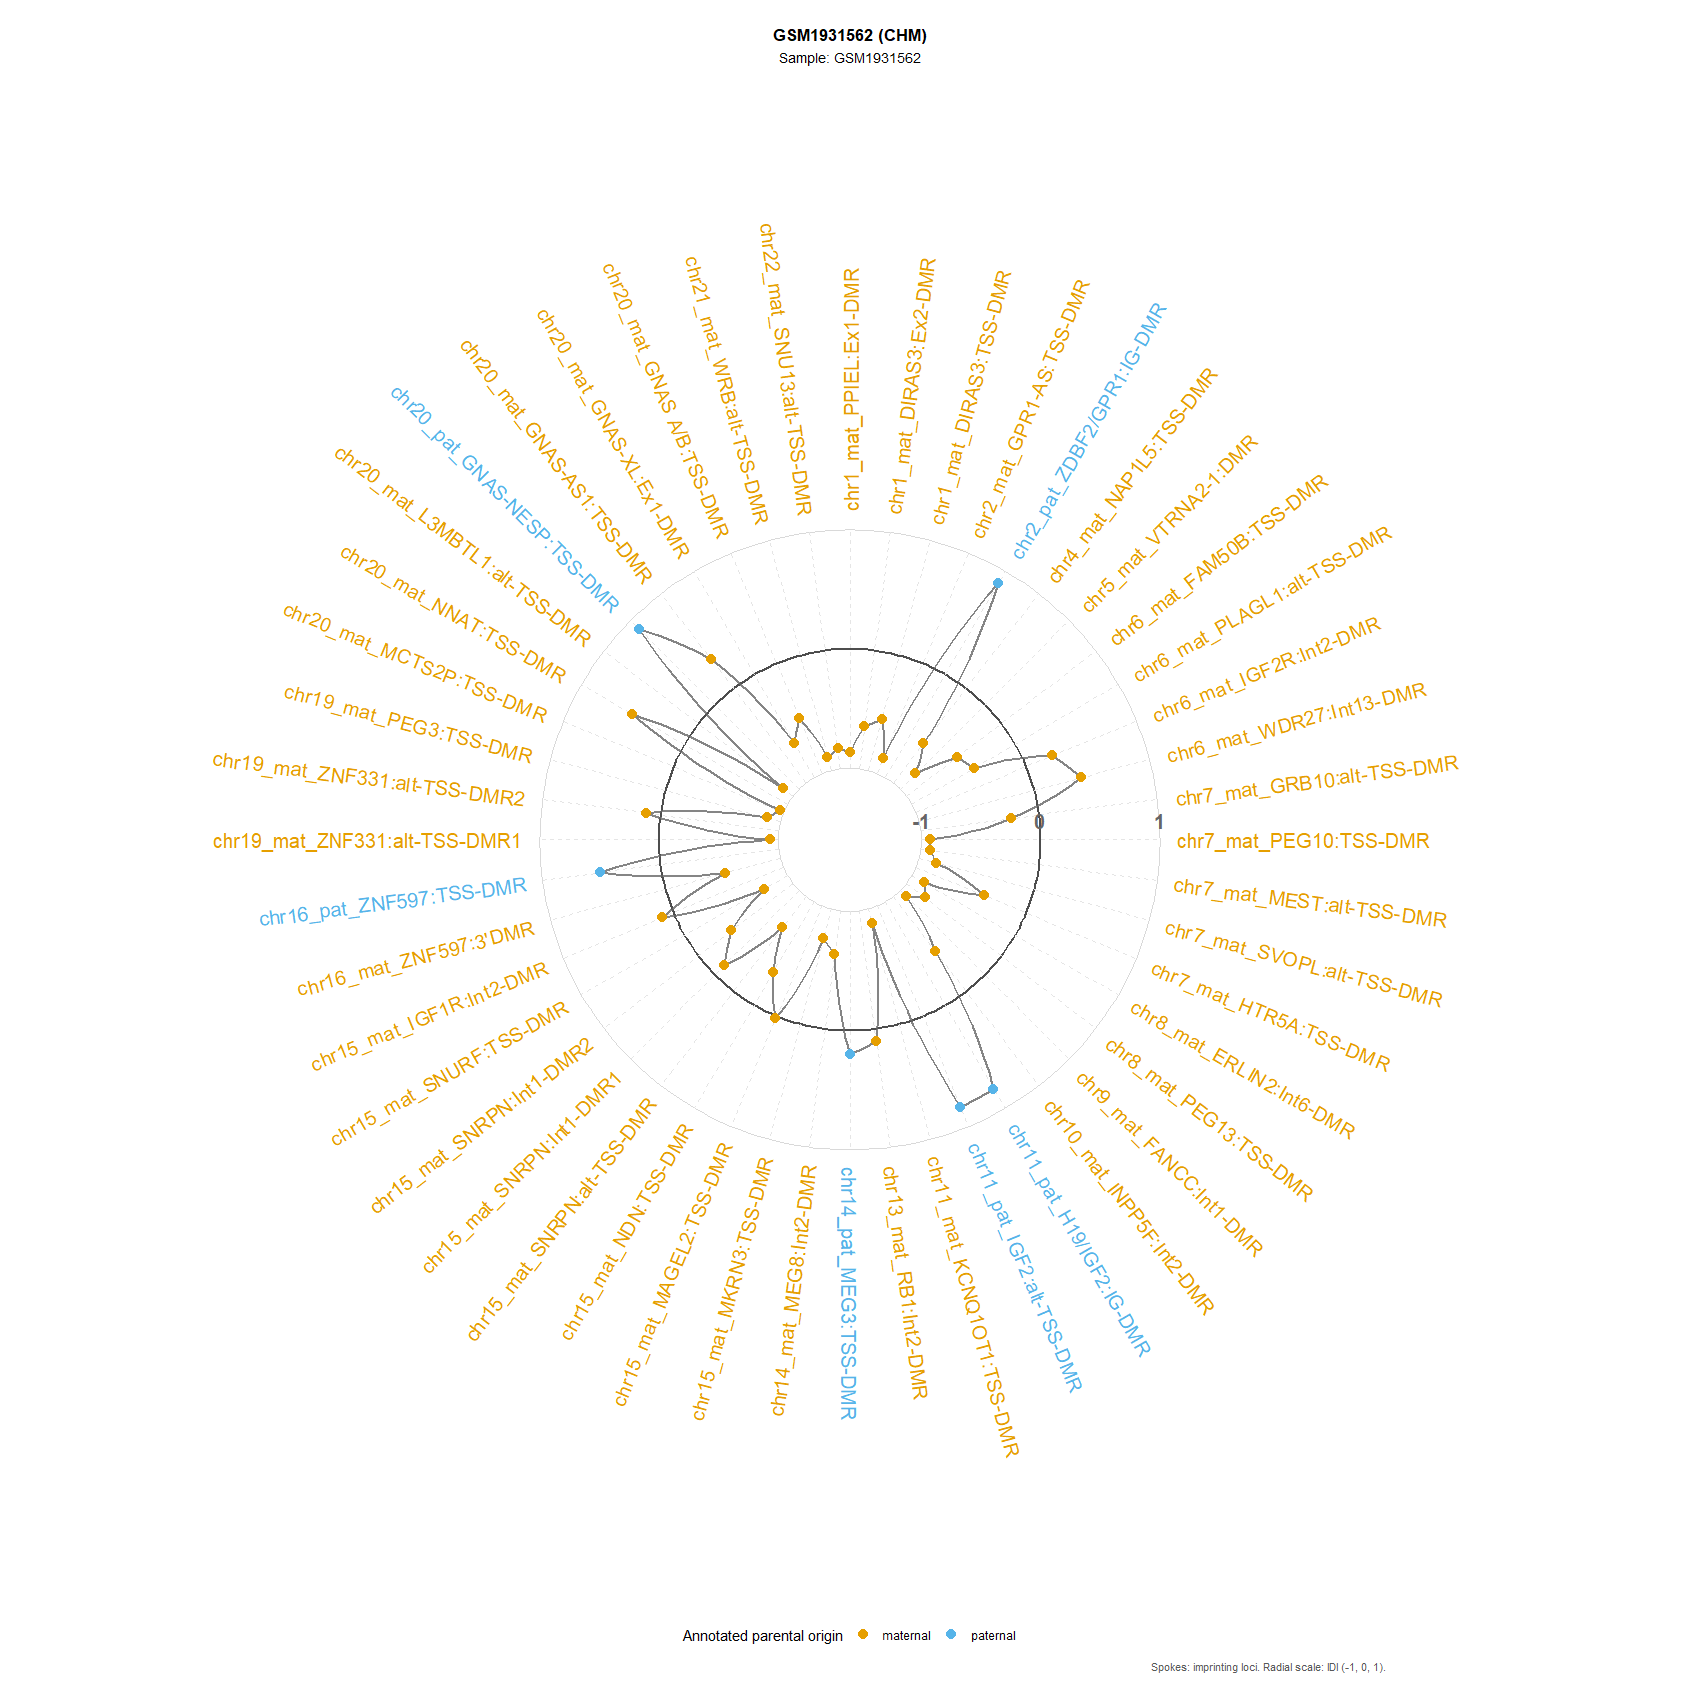

In [16]:
chm <- status$Sample_Name[status$Sample_Group == "CHM"][1]
options(repr.plot.width = 17, repr.plot.height = 17)
plot(x, plot_type = "radar", probeset = "selected", sample_id = chm, title = paste(chm, "(CHM)"))

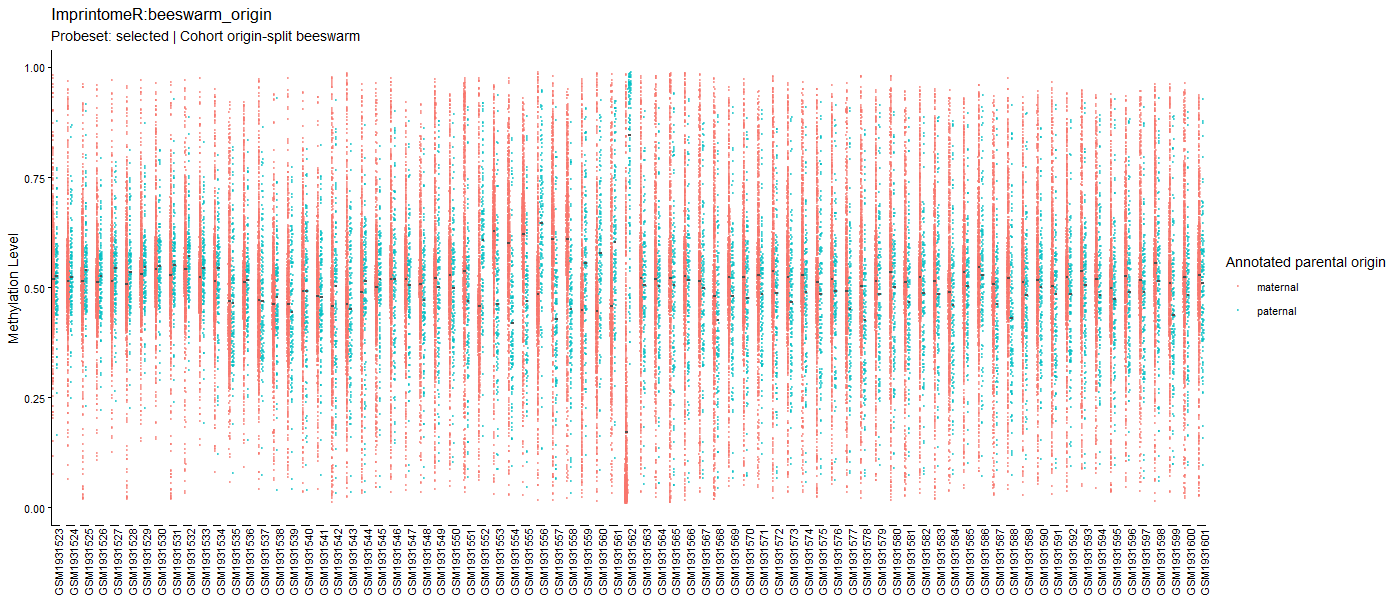

In [17]:
options(repr.plot.width = 14, repr.plot.height = 6)
plot(x, plot_type = "beeswarm_origin", probeset = "selected", SAMPLEID = "Sample_Name")

## Phase 9: Export

In [ ]:
manifest <- export(x, outdir = "GSE74738_imprintome_output", prefix = "GSE74738",
                   save_plots = FALSE, overwrite = TRUE)
head(manifest)

## Session information

In [18]:
local({ si <- sessionInfo(); si$BLAS <- basename(si$BLAS); si$LAPACK <- basename(si$LAPACK); si })

R version 4.3.3 (2024-02-29 ucrt)
Platform: x86_64-w64-mingw32/x64 (64-bit)
Running under: Windows 11 x64 (build 26200)

Matrix products: default


locale:
[1] LC_COLLATE=English_United States.utf8 
[2] LC_CTYPE=English_United States.utf8   
[3] LC_MONETARY=English_United States.utf8
[4] LC_NUMERIC=C                          
[5] LC_TIME=English_United States.utf8    

time zone: America/Chicago
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] dplyr_1.1.4       imprintomeR_1.5.0

loaded via a namespace (and not attached):
 [1] utf8_1.2.4            tidyr_1.3.1           generics_0.1.4       
 [4] shape_1.4.6.1         stringi_1.8.4         digest_0.6.36        
 [7] magrittr_2.0.3        grid_4.3.3            RColorBrewer_1.1-3   
[10] iterators_1.0.14      circlize_0.4.18       foreach_1.5.2        
[13] doParallel_1.0.17     plyr_1.8.9            jsonlite_1.8.8       
[16] ggrepel_